# Used car prices: which brands hold their value, and what is a car worth?

Two questions, answered with about 97,000 real used car listings from the UK (2020):

1. **Depreciation:** after accounting for model, mileage and specs, which brands lose value fastest? Do BMWs really depreciate faster than Toyotas?
2. **Pricing:** how accurately can a model estimate a used car's price from its listing details?

**Short answers.** Toyota holds value best: a Toyota keeps about **90% of its value each year**, versus about **87.5% for BMW and Mercedes-Benz**. Over five years that compounds to roughly 61% of value kept for a Toyota versus 51–52% for the German luxury brands. A gradient-boosted model prices cars to within **about £1,060 on average (6.5% error)**, about half the error of pricing by comparable listings.

## 1. Data

The data is the "100,000 UK Used Car" dataset: listings scraped in 2020, one file per brand, nine brands. Each listing has model, year, price (£), transmission, mileage, fuel type, annual road tax, fuel economy (mpg) and engine size.

Since every listing is from 2020, a car's **age is `2020 − year`**.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.inspection import permutation_importance

from data import load_raw, clean
from depreciation import fit_depreciation, fit_depreciation_curves
from modeling import (FEATURES, GroupMedianBaseline, make_ridge, make_gbm, price_metrics)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

INK, INK_2, GRID, CONTEXT = "#0b0b0b", "#52514e", "#e4e3df", "#c3c2bd"
HIGHLIGHT = {"Toyota": "#2a78d6", "BMW": "#eb6834", "Mercedes-Benz": "#1baf7a"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlecolor": INK, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False,
})
FIG_DIR = "../reports/figures"

In [2]:
raw = load_raw("../data/raw")
print(f"{len(raw):,} raw listings")
raw.head()

99,187 raw listings


,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize,brand
0,A1,2017,12500,Manual,15735,Petrol,150,55.4,1.4,Audi
1,A6,2016,16500,Automatic,36203,Diesel,20,64.2,2.0,Audi
2,A1,2016,11000,Manual,29946,Petrol,30,55.4,1.4,Audi
3,A4,2017,16800,Automatic,25952,Diesel,145,67.3,2.0,Audi
4,A3,2019,17300,Manual,1998,Petrol,145,49.6,1.0,Audi


## 2. Cleaning

Three problems turned up while profiling the raw data:

- **One Ford Fiesta listed as a 2060 model**, an obvious typo.
- **1,475 exact duplicate rows**, the same listing captured twice. Keeping them would double-count those cars and leak copies across the train/test split.
- **266 non-electric cars with a 0-litre engine**, a missing value recorded as 0.

All three are dropped. No column has missing values otherwise.

In [3]:
df, removed = clean(raw)
print(pd.Series(removed, name="rows removed").to_string())
print(f"\n{len(df):,} listings after cleaning ({len(raw) - len(df):,} removed, {(len(raw) - len(df)) / len(raw):.1%})")

year after 2020                     1
exact duplicates                 1475
0-litre engine (not electric)     266

97,445 listings after cleaning (1,742 removed, 1.8%)


In [4]:
summary = df.groupby("brand").agg(
    listings=("price", "size"),
    median_price=("price", "median"),
    median_age=("age", "median"),
    median_mileage=("mileage", "median"),
).sort_values("median_price", ascending=False)
summary

,listings,median_price,median_age,median_mileage
brand,,,,
Mercedes-Benz,12848,22299.0,2.0,15420.0
BMW,10619,20320.0,3.0,18673.0
Audi,10513,20000.0,3.0,19360.0
Volkswagen,14878,15491.5,3.0,16550.5
Skoda,6183,12998.0,2.0,14663.0
Hyundai,4727,11995.0,3.0,17604.0
Ford,17759,11290.0,3.0,18291.0
Toyota,6693,10798.0,3.0,18572.0
Vauxhall,13225,9998.0,3.0,19000.0


## 3. Depreciation: which brands hold their value?

**Why not just compare average prices by age?** Because the brands sell very different cars. Mercedes-Benz's listings include G-Class and S-Class models, while Toyota's are dominated by Aygos and Yarises, and older cars also tend to have more miles. A raw comparison would mix up brand, model and mileage.

**Approach.** Compare each car only with cars **of the same model**, and hold mileage, engine size, fuel type and transmission constant:

$$\log(\text{price}) = \text{model effect} + \beta_{\text{brand}} \cdot \text{age} + \text{controls} + \varepsilon$$

$e^{\beta_{\text{brand}}}$ is the share of value a car keeps each year. The model effects come from subtracting each model's averages before fitting, which is equivalent to one dummy variable per model. Standard errors are robust to unequal variance (HC1).

Cars older than 12 years (about 0.5% of listings) are excluded: they are rare and partly classic cars, which follow different pricing.

In [5]:
dep_data = df[df["age"] <= 12]
brand_table, coef = fit_depreciation(dep_data)

print(f"Fitted on {coef.attrs['n']:,} listings; within-model R² = {coef.attrs['r2_within']:.3f}\n")
show = brand_table.assign(
    yearly_value_kept=lambda t: t["yearly_value_kept"].map("{:.1%}".format),
    ci_95=lambda t: [f"[{lo:.1%}, {hi:.1%}]" for lo, hi in zip(t["kept_ci_low"], t["kept_ci_high"])],
    value_after_3y=lambda t: t["value_after_3y"].map("{:.0%}".format),
    value_after_5y=lambda t: t["value_after_5y"].map("{:.0%}".format),
)[["brand", "listings", "yearly_value_kept", "ci_95", "value_after_3y", "value_after_5y"]]
show

Fitted on 96,963 listings; within-model R² = 0.815



,brand,listings,yearly_value_kept,ci_95,value_after_3y,value_after_5y
0,Toyota,6629,90.5%,"[90.3%, 90.8%]",74%,61%
1,Skoda,6173,89.0%,"[88.6%, 89.4%]",70%,56%
2,Volkswagen,14823,88.8%,"[88.6%, 89.0%]",70%,55%
3,Hyundai,4714,88.4%,"[88.1%, 88.7%]",69%,54%
4,Vauxhall,13158,88.3%,"[88.0%, 88.5%]",69%,54%
5,Audi,10467,87.9%,"[87.7%, 88.0%]",68%,52%
6,BMW,10552,87.7%,"[87.6%, 87.9%]",68%,52%
7,Mercedes-Benz,12762,87.5%,"[87.3%, 87.7%]",67%,51%
8,Ford,17685,86.9%,"[86.7%, 87.1%]",66%,50%


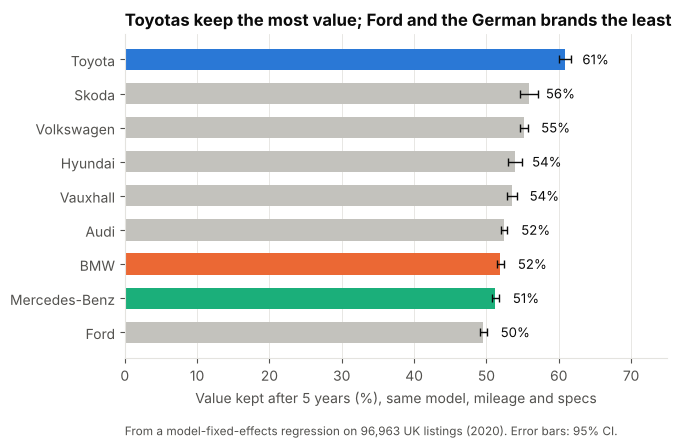

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.2))
t = brand_table.sort_values("value_after_5y")
colors = [HIGHLIGHT.get(b, CONTEXT) for b in t["brand"]]
ax.barh(t["brand"], t["value_after_5y"] * 100, color=colors, height=0.62)
err_lo = (t["value_after_5y"] - t["kept_ci_low"] ** 5) * 100
err_hi = (t["kept_ci_high"] ** 5 - t["value_after_5y"]) * 100
ax.errorbar(t["value_after_5y"] * 100, t["brand"], xerr=[err_lo, err_hi], fmt="none", ecolor=INK, capsize=3, lw=1)
for y, v in enumerate(t["value_after_5y"]):
    ax.text(v * 100 + 2.4, y, f"{v:.0%}", va="center", color=INK, fontsize=9.5)
ax.set_xlim(0, 75)
ax.set_xlabel("Value kept after 5 years (%), same model, mileage and specs")
ax.grid(axis="y", visible=False)
ax.set_title("Toyotas keep the most value; Ford and the German brands the least", loc="left")
ax.text(0, -0.24, "From a model-fixed-effects regression on 96,963 UK listings (2020). Error bars: 95% CI.",
        transform=ax.transAxes, color=INK_2, fontsize=8.5)
fig.savefig(f"{FIG_DIR}/value_kept_after_5y.png")
plt.show()

### Is depreciation really a constant percentage per year?

The estimate above assumes each brand loses the same percentage every year. To check, refit with a separate effect for every brand and age (0 to 7 years, where most listings are), again comparing within models.

In [7]:
curves = fit_depreciation_curves(dep_data, max_age=7)
curve_table = curves.pivot(index="age", columns="brand", values="value_kept")
curve_table.map(lambda v: f"{v:.0%}")

brand,Audi,BMW,Ford,Hyundai,Mercedes-Benz,Skoda,Toyota,Vauxhall,Volkswagen
age,,,,,,,,,
0,100%,100%,100%,100%,100%,100%,100%,100%,100%
1,92%,99%,95%,86%,92%,92%,94%,90%,92%
2,81%,81%,82%,75%,77%,82%,85%,82%,84%
3,71%,72%,70%,69%,69%,75%,79%,74%,74%
4,62%,64%,63%,62%,63%,67%,74%,66%,67%
5,55%,58%,54%,54%,54%,62%,67%,58%,58%
6,48%,51%,49%,49%,49%,53%,60%,49%,52%
7,43%,45%,43%,40%,41%,48%,53%,44%,46%


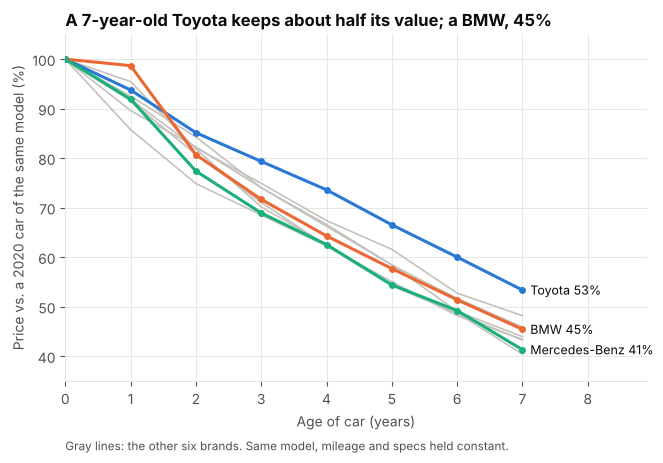

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for brand, g in curves.groupby("brand"):
    if brand not in HIGHLIGHT:
        ax.plot(g["age"], g["value_kept"] * 100, color=CONTEXT, lw=1.2, zorder=1)
for brand, color in HIGHLIGHT.items():
    g = curves[curves["brand"] == brand]
    ax.plot(g["age"], g["value_kept"] * 100, color=color, lw=2.2, marker="o", ms=4, zorder=3)
    last = g.iloc[-1]
    ax.text(last["age"] + 0.12, last["value_kept"] * 100, f"{brand} {last['value_kept']:.0%}",
            va="center", color=INK, fontsize=9)
ax.text(0, -0.2, "Gray lines: the other six brands. Same model, mileage and specs held constant.",
        transform=ax.transAxes, color=INK_2, fontsize=8.5)
ax.set_xlim(0, 8.9)
ax.set_ylim(35, 105)
ax.set_xlabel("Age of car (years)")
ax.set_ylabel("Price vs. a 2020 car of the same model (%)")
ax.set_title("A 7-year-old Toyota keeps about half its value; a BMW, 45%", loc="left")
fig.savefig(f"{FIG_DIR}/depreciation_curves.png")
plt.show()

The curves are close to straight on a percentage basis, so the constant-rate summary is a fair description. Two details are worth knowing:

- **The first year is noisy.** "Age 0" means a 2020 model listed in 2020: mostly nearly-new and ex-demonstrator cars, not showroom prices. BMW's 1-year-old cars sell for almost the same as its 2020 ones, which probably reflects how those demo cars are priced rather than BMWs not depreciating.
- **The ranking is stable from year 3 onward.** Toyota stays on top at every age, and BMW and Mercedes-Benz stay near the bottom.

Mileage matters too, but less than age once the model is fixed: holding age constant, doubling the mileage lowers the price by about 2.5% (coefficient −0.037 on log mileage).

## 4. Price model: how much is a car worth?

**Setup.** Predict `log(price)` from brand, model, age, mileage, transmission, fuel type, engine size, mpg and road tax. Training on the log means errors are treated as percentages, so a £1,000 miss counts more on a £5,000 car than on a £50,000 one. Results are reported in pounds.

**Split.** 80% train and 20% test, stratified by brand. The test set is used **once**, at the end. Model settings are chosen with 3-fold cross-validation inside the training set.

**Models compared:**
1. **Baseline:** the median price of training cars with the same brand, model and year. This is roughly what a person does when comparing similar listings, so a real model has to beat it.
2. **Ridge regression:** a linear model on one-hot categories and scaled numbers.
3. **Gradient-boosted trees** (scikit-learn's `HistGradientBoostingRegressor`), which can learn interactions such as "mileage hurts a BMW M4 more than a Fiesta".

In [9]:
X = df[FEATURES + ["year"]]
y = np.log(df["price"])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=df["brand"])
print(f"Train: {len(X_train):,} listings   Test: {len(X_test):,} listings")

Train: 77,956 listings   Test: 19,489 listings


In [10]:
# Tune the gradient-boosted model with 3-fold CV on the training set only.
grid = [
    {"learning_rate": 0.1, "max_leaf_nodes": 31},
    {"learning_rate": 0.1, "max_leaf_nodes": 63},
    {"learning_rate": 0.05, "max_leaf_nodes": 63},
    {"learning_rate": 0.05, "max_leaf_nodes": 127},
]
kf = KFold(n_splits=3, shuffle=True, random_state=0)
cv_rows = []
for params in grid:
    maes = []
    for tr_idx, va_idx in kf.split(X_train):
        m = make_gbm(max_iter=1500, **params).fit(X_train.iloc[tr_idx][FEATURES], y_train.iloc[tr_idx])
        pred = np.exp(m.predict(X_train.iloc[va_idx][FEATURES]))
        maes.append(price_metrics(np.exp(y_train.iloc[va_idx]), pred)["MAE (£)"])
    cv_rows.append({**params, "cv_MAE (£)": np.mean(maes), "fold_sd (£)": np.std(maes)})
cv_results = pd.DataFrame(cv_rows).sort_values("cv_MAE (£)").reset_index(drop=True)
best_params = {"learning_rate": float(cv_results.loc[0, "learning_rate"]),
               "max_leaf_nodes": int(cv_results.loc[0, "max_leaf_nodes"])}
print("Best settings:", best_params)
cv_results.style.format({"cv_MAE (£)": "£{:,.0f}", "fold_sd (£)": "£{:,.0f}"})

Best settings: {'learning_rate': 0.05, 'max_leaf_nodes': 127}


,learning_rate,max_leaf_nodes,cv_MAE (£),fold_sd (£)
0,0.050000,127,"£1,081",£5
1,0.050000,63,"£1,083",£6
2,0.100000,63,"£1,086",£7
3,0.100000,31,"£1,095",£5


In [11]:
baseline = GroupMedianBaseline().fit(X_train, y_train)
ridge = make_ridge(alpha=1.0).fit(X_train[FEATURES], y_train)
gbm = make_gbm(max_iter=1500, **best_params).fit(X_train[FEATURES], y_train)

actual = np.exp(y_test)
preds = {
    "Baseline (median of similar listings)": np.exp(baseline.predict(X_test)),
    "Ridge regression": np.exp(ridge.predict(X_test[FEATURES])),
    "Gradient-boosted trees": np.exp(gbm.predict(X_test[FEATURES])),
}
results = pd.DataFrame({name: price_metrics(actual, p) for name, p in preds.items()}).T
results.style.format({"MAE (£)": "£{:,.0f}", "median abs error (£)": "£{:,.0f}", "MAPE": "{:.1%}", "R²": "{:.3f}"})

,MAE (£),median abs error (£),MAPE,R²
Baseline (median of similar listings),"£2,113","£1,255",13.0%,0.833
Ridge regression,"£1,627","£1,058",9.5%,0.914
Gradient-boosted trees,"£1,060",£694,6.5%,0.960


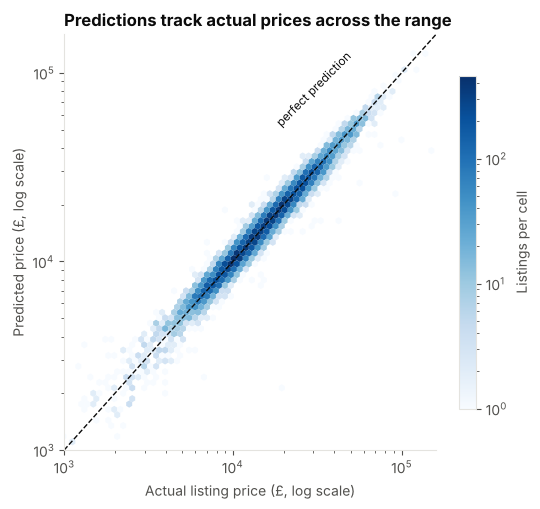

In [12]:
fig, ax = plt.subplots(figsize=(6, 5.4))
p = preds["Gradient-boosted trees"]
hb = ax.hexbin(actual, p, gridsize=70, xscale="log", yscale="log", bins="log",
               cmap="Blues", mincnt=1, linewidths=0)
lims = [1_000, 160_000]
ax.plot(lims, lims, color=INK, lw=1, ls="--")
ax.text(30_000, 52_000, "perfect prediction", color=INK, fontsize=8.5, rotation=45, ha="center")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("Actual listing price (£, log scale)")
ax.set_ylabel("Predicted price (£, log scale)")
ax.set_title("Predictions track actual prices across the range", loc="left")
cb = fig.colorbar(hb, ax=ax, shrink=0.8)
cb.set_label("Listings per cell", color=INK_2)
ax.grid(False)
fig.savefig(f"{FIG_DIR}/predicted_vs_actual.png")
plt.show()

### Where does the model struggle?

In [13]:
test = X_test.assign(actual=actual, pred=preds["Gradient-boosted trees"])
test["abs_pct_err"] = (test["pred"] - test["actual"]).abs() / test["actual"]

by_brand = test.groupby("brand")["abs_pct_err"].agg(["mean", "median"]).sort_values("mean")
by_brand.columns = ["mean % error", "median % error"]
print("Error by brand:")
print(by_brand.map("{:.1%}".format).to_string())

test["price_band"] = pd.qcut(test["actual"], 5, labels=["cheapest 20%", "20-40%", "40-60%", "60-80%", "priciest 20%"])
by_band = test.groupby("price_band", observed=True)["abs_pct_err"].mean()
print("\nMean % error by price band:")
print(by_band.map("{:.1%}".format).to_string())

Error by brand:
              mean % error median % error
brand                                    
Volkswagen            5.9%           4.5%
Toyota                6.2%           4.7%
Mercedes-Benz         6.2%           4.5%
Hyundai               6.3%           4.8%
Vauxhall              6.6%           5.1%
BMW                   6.7%           5.1%
Ford                  6.7%           5.1%
Audi                  6.8%           5.4%
Skoda                 6.9%           5.6%

Mean % error by price band:
price_band
cheapest 20%    8.0%
20-40%          5.9%
40-60%          6.2%
60-80%          5.8%
priciest 20%    6.4%


In [14]:
cols = ["brand", "model", "year", "mileage", "fuelType", "engineSize", "actual", "pred", "abs_pct_err"]
worst = test.sort_values("abs_pct_err", ascending=False)[cols].head(8)
worst.style.format({"actual": "£{:,.0f}", "pred": "£{:,.0f}", "abs_pct_err": "{:.0%}", "mileage": "{:,}"})

,brand,model,year,mileage,fuelType,engineSize,actual,pred,abs_pct_err
55358,Mercedes-Benz,A Class,2010,"116,126",Diesel,2.000000,"£1,350","£3,534",162%
69036,Toyota,Avensis,2007,"120,000",Petrol,1.800000,"£1,200","£2,780",132%
54527,Mercedes-Benz,S Class,2001,"108,800",Diesel,3.200000,"£1,695","£3,841",127%
3067,Audi,A1,2016,"30,000",Petrol,2.000000,"£8,695","£18,674",115%
34535,Ford,Focus,2009,"50,000",Petrol,1.600000,"£1,950","£3,820",96%
55208,Mercedes-Benz,M Class,2004,"121,000",Diesel,2.700000,"£19,950","£2,145",89%
55360,Mercedes-Benz,S Class,2002,"24,000",Petrol,5.000000,"£6,995","£12,959",85%
44737,Mercedes-Benz,GLE Class,2018,"42,882",Diesel,2.100000,"£15,491","£27,472",77%


The model is a little less accurate on the cheapest fifth of cars (8.0% average error versus about 6% elsewhere), and the biggest percentage misses show why:

- **Old, high-mileage cars listed under £2,000.** A £2,000 miss on a £1,500 car is a huge percentage, and at that age the price depends mostly on condition, which the data doesn't record.
- **A few likely data problems.** A 2004 Mercedes M-Class with 121,000 miles listed at £19,950 is far above anything comparable. It could be a typo, a rare AMG version, or a car with an unusual history; the model has no way to know.

Neither is something more model tuning would fix; it would take better data (condition, trim, service history).

### What drives the predictions?

Permutation importance: shuffle one feature at a time in the test set and measure how much worse the model gets. A big increase means the model leans on that feature.

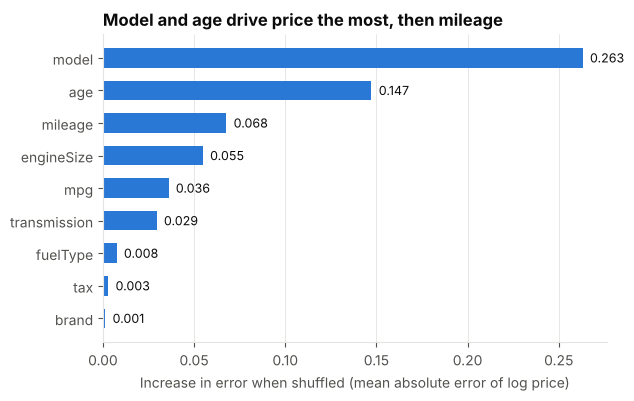

In [15]:
sample = X_test.sample(5000, random_state=1)
imp = permutation_importance(gbm, sample[FEATURES], y_test.loc[sample.index],
                             scoring="neg_mean_absolute_error", n_repeats=5, random_state=0)
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.barh(importance.index, importance.values, color="#2a78d6", height=0.6)
for y_, v in enumerate(importance.values):
    ax.text(v + 0.004, y_, f"{v:.3f}", va="center", color=INK, fontsize=9)
ax.set_xlabel("Increase in error when shuffled (mean absolute error of log price)")
ax.grid(axis="y", visible=False)
ax.set_title("Model and age drive price the most, then mileage", loc="left")
fig.savefig(f"{FIG_DIR}/feature_importance.png")
plt.show()

**Model** matters most, since it sets the starting price, followed by **age** and **mileage**. **Brand** scores near zero, which doesn't mean brand is unimportant: the model name already identifies the brand, so shuffling the brand column alone loses almost no information.

## 5. Using the model: what will this car be worth?

A practical use: estimate what a specific car will sell for as it ages. Below, a BMW 3 Series and a Toyota C-HR, both bought in 2020, driven 8,000 miles a year, priced by the model at each age. (Fuel economy and tax are filled in with the median for that model.)

In [16]:
def car_value_path(brand, model, transmission, fuel, engine, miles_per_year=8_000, years=7):
    ref = df[(df["brand"] == brand) & (df["model"] == model)]
    rows = pd.DataFrame({
        "brand": brand, "model": model, "transmission": transmission, "fuelType": fuel,
        "engineSize": engine, "age": range(years + 1),
        "mpg": ref["mpg"].median(), "tax": ref["tax"].median(),
    })
    rows["mileage"] = rows["age"] * miles_per_year + 1_000
    rows["predicted_price"] = np.exp(gbm.predict(rows[FEATURES]))
    rows["value_kept"] = rows["predicted_price"] / rows["predicted_price"].iloc[0]
    return rows[["age", "mileage", "predicted_price", "value_kept"]]

bmw = car_value_path("BMW", "3 Series", "Automatic", "Diesel", 2.0)
toyota = car_value_path("Toyota", "C-HR", "Automatic", "Hybrid", 1.8)
paths = pd.concat({"BMW 3 Series": bmw, "Toyota C-HR": toyota}, axis=1)
paths.style.format({c: ("£{:,.0f}" if c[1] == "predicted_price" else "{:.0%}" if c[1] == "value_kept" else "{:,}")
                    for c in paths.columns})

The model predicts the BMW keeps about 59% of its value after 3 years and 35% after 7, versus 70% and 43% for the Toyota C-HR. These paths fall faster than the brand-level rates in section 3 because here the mileage also climbs every year, while section 3 holds mileage fixed. That is closer to what a real owner experiences.

## 6. Conclusions

**Depreciation.** Holding model, mileage and specs fixed, **Toyota keeps about 90% of its value per year, the best of the nine brands**. Ford, Mercedes-Benz, BMW and Audi lose the most, keeping about 87–88% a year. A few percentage points compound: after five years a Toyota keeps about 61% of its value and a BMW about 52%.

**Pricing.** Gradient-boosted trees estimate listing prices to within **about £1,060 on average (6.5%)**, roughly half the error of pricing by comparable listings (£2,113) and well ahead of a linear model (£1,627). Accuracy is similar across brands (5.9–6.9%). The model is weakest on old, cheap, high-mileage cars, where condition, which isn't in the data, decides the price.

## 7. Limitations

- **Listing prices, not sale prices.** Asking prices are usually somewhat above what cars actually sell for.
- **One snapshot.** All listings are from 2020, so "depreciation" compares cars of different ages at the same moment, not the same car tracked over time. Model changes and facelifts between years are part of what is being measured.
- **UK market only.** Brand reputations and the used market differ in the US.
- **Condition and trim aren't recorded.** Two "3 Series 2017 diesel" cars can differ a lot in spec and condition; that's a large share of the error the model can't explain.
- **Point predictions.** The model gives one price; a real pricing tool should also give a range, for example with quantile regression.